<a href="https://colab.research.google.com/github/jovanfranco/usdmxn-volatilidad/blob/main/clase4_normal_colas_gordas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

datos = yf.download("MXN=X", start="2022-01-01", progress=False)
cierre = datos["Close"].squeeze()
rend = cierre.pct_change().dropna()

/tmp/ipykernel_4141/2709322883.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download("MXN=X", start="2022-01-01", progress=False)


In [2]:
z = (rend - rend.mean()) / rend.std()
print("Días totales:", len(z))
print("Días a más de 3 desviaciones:", int((z.abs() > 3).sum()))
print("Esperados si fuera normal:", round(len(z) * 0.0027, 1))
print("Curtosis en exceso:", round(float(stats.kurtosis(rend)), 2))

Días totales: 1247
Días a más de 3 desviaciones: 16
Esperados si fuera normal: 3.4
Curtosis en exceso: 3.81


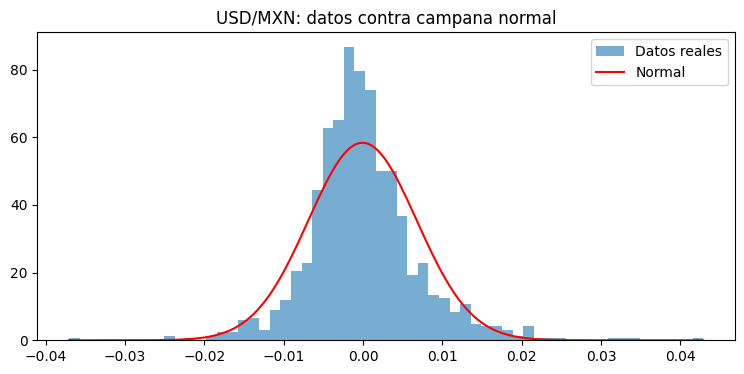

In [3]:
x = np.linspace(rend.min(), rend.max(), 200)

plt.figure(figsize=(9, 4))
plt.hist(rend, bins=60, density=True, alpha=0.6, label="Datos reales")
plt.plot(x, stats.norm.pdf(x, rend.mean(), rend.std()), color="red", label="Normal")
plt.title("USD/MXN: datos contra campana normal")
plt.legend()
plt.show()

In [4]:
real = rend.quantile(0.01)
normal = stats.norm.ppf(0.01, rend.mean(), rend.std())
print("Percentil 1% real:", round(float(real), 4))
print("Percentil 1% normal:", round(float(normal), 4))

Percentil 1% real: -0.0159
Percentil 1% normal: -0.016


In [5]:
for q in [0.05, 0.01, 0.005, 0.001]:
    real_b = rend.quantile(q)
    norm_b = stats.norm.ppf(q, rend.mean(), rend.std())
    real_a = rend.quantile(1 - q)
    norm_a = stats.norm.ppf(1 - q, rend.mean(), rend.std())
    print(f"{q:.3f} | Baja real {real_b:.4f} normal {norm_b:.4f} | Sube real {real_a:.4f} normal {norm_a:.4f}")

0.050 | Baja real -0.0098 normal -0.0113 | Sube real 0.0120 normal 0.0112
0.010 | Baja real -0.0159 normal -0.0160 | Sube real 0.0203 normal 0.0158
0.005 | Baja real -0.0180 normal -0.0177 | Sube real 0.0222 normal 0.0176
0.001 | Baja real -0.0244 normal -0.0212 | Sube real 0.0342 normal 0.0211


In [6]:
extremos = z[z.abs() > 3]
print(extremos.round(2))
print(extremos.groupby(extremos.index.year).count())

Date
2022-03-10   -3.12
2022-06-14    3.28
2022-08-03    3.08
2023-03-14    4.82
2023-03-16    3.09
2024-06-04    6.28
2024-06-07    3.15
2024-06-10    3.66
2024-08-05    4.68
2024-08-09   -3.58
2024-08-28    3.00
2025-02-03    3.51
2025-02-04   -5.41
2025-04-07    5.07
2025-04-10   -3.52
2026-03-04    3.12
Name: MXN=X, dtype: float64
Date
2022    3
2023    2
2024    6
2025    4
2026    1
Name: MXN=X, dtype: int64
